# **TB2 (Hito 2) - Grafo de proteínas de la tuberculosis**
Complejidad Algorítmica
Grupo 3
Caso 3: Análisis de redes biológicas

Datos: **STRING v12.5**, bacteria *M. tuberculosis* H37Rv.

* **Nodo** = una proteína de la bacteria
* **Arista** = una interacción entre dos proteínas
* **Peso** = confianza de que esa interacción existe (0 a 1000)

**Enlaces de los archivos a usar:**
https://stringdb-downloads.org/download/protein.links.v12.5/83332.protein.links.v12.5.txt.gz

https://stringdb-downloads.org/download/protein.info.v12.5/83332.protein.info.v12.5.txt.gz

Secciones 1 a 14: TB1. **Lo nuevo del Hito 2 empieza en la sección 15.**

## **1. Subir los archivos**

In [1]:
# Subimos los 2 archivos que bajamos de STRING
from google.colab import files
files.upload()

Saving 83332.protein.links.v12.5.txt.gz to 83332.protein.links.v12.5.txt.gz
Saving 83332.protein.info.v12.5.txt.gz to 83332.protein.info.v12.5.txt.gz


{'83332.protein.links.v12.5.txt.gz': b'\x1f\x8b\x08\x00\x00\x00\x00\x00\x02\x03|\xbdK\xae.\xb9\x0e\xa5\xd7\xf7(\xf6\x08\x8c\x10\xa9g3\xa7\xe0\t\x14\xe0\xedjT\xc3U\x85\xb2\xe1\xf1\x9b\xa4\xf6\x05B\x8a\xfc\xd89\'\x0fV\xea\x0f=)\x92"\x17\xff\xe7\xff\xfa\x1f\xff\xef\x7f\xfdo\xff\xbd\xfc\xfc\xcf\xfd\x1f\xf2\xf3\xfb?\xfe\xef\xff\xf3\xbf\xfd\xf7\xff\xfa\x7f\xfd\x97\xff\xe7\xf7\x7f\xfc\xaf\xff\xfa\xbfMU\x95\xff\xfd\xff\xf8\xff\x9e\xe7)?\xaf\x7f\xc8\xcfZ\x03Q\xfdY\xda\x11\xad?\xf2TD\xdb\xcf|&\xa2\xfdg\n\xfery~\x7fD\n\xc2\xe5\xf7\xa7\x0c\xfc\xed\xa2?\xad4D\xab\xfd\xf6\xa3\x087\xfb\xed\xc9\x9f\x1e\x06\xf7\x87`\x91\xdf\x1f\x9d8\'\xb5\xfc\xc8\xc2OW\xfbmi\x087\xcd\xe6\xa4\xd5\x9f\xfa\xe0\x84\xb6\xf6#\x95\xd1nmq\x13\xb4aC\xc2\x11\xb7\xf9\xb3\x1a\xa2C\x7f\xca\xa2\xe9(\xbeP\xb8EJ\x19?\x82\xcbX\xc4\xb6HY\x82\xb0\r\x18wHQ\xdf\xb94\x1d\xa5\x1a:\x16\xa2\xc3\xf6\x07\xb6\xb5\xe9\x90\x87\x16\xc9\xda\xd9\x12b\xaf\xe6\xb2\xf5\x9f\xb4\x0eb\x07*C\xa7\x1f\x19\xda<\x86\xfc&\xdd\x16\xad9<\x92~K\xf3\xe3\xd8\x19\x16\x

In [2]:
# Vienen comprimidos así que los descomprimimos
!gunzip -kf 83332.protein.info.v12.5.txt.gz
!gunzip -kf 83332.protein.links.v12.5.txt.gz
!ls -lh *.txt

-rw-r--r-- 1 root root 1.6M Nov 11 19:00 83332.protein.info.v12.5.txt
-rw-r--r-- 1 root root  37M Nov 11 19:00 83332.protein.links.v12.5.txt


## **2. Leer las proteínas**
Cada fila es así: `83332.Rv0667   rpoB   1172   descripción...`

In [3]:
# Guardamos el nombre corto de cada proteína
# ej: nombre["83332.Rv0667"] = "rpoB"
nombre = {}

with open("83332.protein.info.v12.5.txt") as f:
  f.readline()  # la primera línea son los títulos
  for linea in f:
    datos = linea.split("\t")  # las columnas están separadas por tabulaciones
    nombre[datos[0]] = datos[1]

print("Total de proteínas:", len(nombre))

Total de proteínas: 4026


## **3. Armar el grafo (lista de adyacencia)**
Igual que `ady_list` cada proteína guarda la lista de sus vecinas.

In [4]:
# grafo["rpoB"] = ["rpoC", "rpoA", ...]   (lista de adyacencia)
# peso[("rpoB", "rpoC")] = 999            (confianza de la arista)
def construir_grafo(umbral):
  grafo = {}
  peso = {}
  with open("83332.protein.links.v12.5.txt") as f:
    f.readline()  # cabecera
    for linea in f:
      p1, p2, puntaje = linea.split()
      puntaje = int(puntaje)
      if puntaje >= umbral:  # nos quedamos solo con las confiables
        u = nombre[p1]
        v = nombre[p2]
        if u not in grafo:
          grafo[u] = []
        grafo[u].append(v)
        peso[(u, v)] = puntaje
  return grafo, peso


# El archivo trae cada par 2 veces (A-B y B-A), por eso dividimos entre 2 (siempre sera no dirigido)
def contar_aristas(grafo):
  total = 0
  for u in grafo:
    total += len(grafo[u])
  return total // 2

## **4. BFS (búsqueda en amplitud)**


In [5]:
# nivel[v] = a cuántos pasos está v desde s
# max_nivel = hasta qué profundidad buscamos (profundidad limitada)
def bfs(G, s, max_nivel=None):
  visited = {s: True}
  path = {s: -1}
  nivel = {s: 0}
  queue = [s]

  while queue:
    u = queue.pop(0)  # sacamos el primero de la cola (FIFO)
    if nivel[u] == max_nivel:
      continue        # no seguimos más allá del nivel máximo
    for v in G[u]:
      if v not in visited:
        visited[v] = True
        path[v] = u
        nivel[v] = nivel[u] + 1
        queue.append(v)
  return path, nivel

## **5. DFS (búsqueda en profundidad)**

In [6]:
import sys
sys.setrecursionlimit(10000)  # Python solo deja 1000 llamadas recursivas seguidas, se aumenta el limite

def dfs(G, s):
  path = {s: -1}
  visited = {}

  def _dfs(u):
    visited[u] = True
    for v in G[u]:
      if v not in visited:
        path[v] = u
        _dfs(v)

  _dfs(s)
  return path

## **6. Componentes conexas**
Una componente conexa es un grupo de proteínas conectadas entre sí pero sin conexión con el resto.

In [7]:
# Lanzamos un recorrido desde cada nodo que aún no se visitó, todo lo que alcanza ese recorrido es una componente
def componentes_conexas(G, recorrido):
  componentes = []
  visto = {}
  for s in G:
    if s not in visto:
      if recorrido == "bfs":
        path, nivel = bfs(G, s)
      else:
        path = dfs(G, s)
      componente = list(path.keys())  # todos los nodos alcanzados desde s
      for v in componente:
        visto[v] = True
      componentes.append(componente)
  return componentes


def tamanio_mayor(componentes):
  mayor = 0
  for c in componentes:
    if len(c) > mayor:
      mayor = len(c)
  return mayor

## **7. Elegir el umbral de confianza**
Probamos 3 umbrales. El enunciado pide al menos 1500 nodos.

In [8]:
print("Umbral | Nodos | Aristas | Componentes | Comp. mayor")
for umbral in [400, 700, 900]:
  G, P = construir_grafo(umbral)
  comps = componentes_conexas(G, "bfs")
  print(umbral, "|", len(G), "|", contar_aristas(G), "|", len(comps), "|", tamanio_mayor(comps))

Umbral | Nodos | Aristas | Componentes | Comp. mayor
400 | 4013 | 106664 | 6 | 4001
700 | 3802 | 28739 | 46 | 3705
900 | 2744 | 10001 | 274 | 1978


Elegimos **700** (confianza alta en STRING): con 400 entran muchas interacciones dudosas y con 900 la red
se parte en muchos pedazos y se pierden proteínas.

## **8. El grafo final (umbral 700)**

In [9]:
UMBRAL = 700
grafo, peso = construir_grafo(UMBRAL)

N = len(grafo)
aristas = contar_aristas(grafo)
comps_bfs = componentes_conexas(grafo, "bfs")
comps_dfs = componentes_conexas(grafo, "dfs")
mayor = tamanio_mayor(comps_bfs)

print("Nodos:", N)
print("Aristas:", aristas)
print("Componentes con BFS:", len(comps_bfs))
print("Componentes con DFS:", len(comps_dfs))
print("Componente más grande:", mayor)

# ¿Cuánto ocuparía una matriz de adyacencia?
print("Celdas de la matriz:", N * N)
print("Vecinos guardados en la lista:", 2 * aristas)
print("Porcentaje de la matriz con 1:", round(100 * 2 * aristas / (N * N), 2), "%")

Nodos: 3802
Aristas: 28739
Componentes con BFS: 46
Componentes con DFS: 46
Componente más grande: 3705
Celdas de la matriz: 14455204
Vecinos guardados en la lista: 57478
Porcentaje de la matriz con 1: 0.4 %


## **9. Grado de los nodos**

El **grado** de una proteína es cuántas vecinas tiene: `len(grafo[u])`.

In [10]:
grado = {}
for u in grafo:
  grado[u] = len(grafo[u])

grado_max = max(grado.values())
print("Grado promedio:", round(2 * aristas / N, 1))
print("Grado máximo:", grado_max)

# Top 10: vamos del grado más alto al más bajo y vamos guardando
top = []
for g in range(grado_max, 0, -1):
  for u in grafo:
    if grado[u] == g:
      top.append(u)

print("Las 10 proteínas con más interacciones:")
for u in top[:10]:
  print(" ", u, grado[u])

Grado promedio: 15.1
Grado máximo: 164
Las 10 proteínas con más interacciones:
  rplC 164
  rpoB 160
  rplM 157
  fas 154
  rplK 152
  rplB 152
  ppsC 152
  rpsB 149
  pks2 149
  rpsL 147


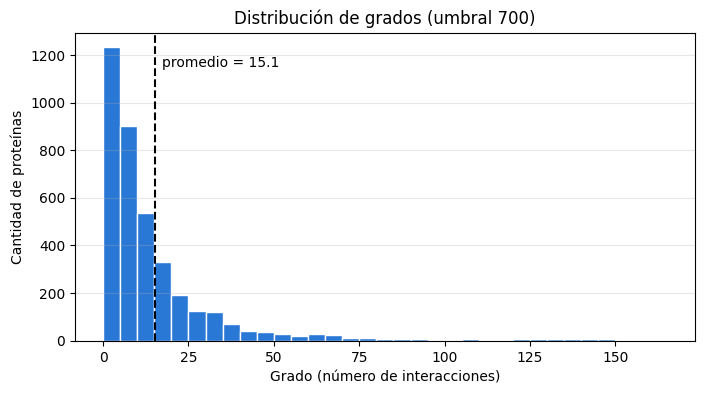

In [11]:
import matplotlib.pyplot as plt

promedio = 2 * aristas / N
plt.figure(figsize=(8, 4))
plt.hist(list(grado.values()), bins=range(0, 170, 5), color="#2a78d6", edgecolor="white")
plt.axvline(promedio, color="black", linestyle="--")  # línea del promedio
plt.text(promedio + 2, 1150, f"promedio = {promedio:.1f}")
plt.grid(axis="y", alpha=0.3)
plt.title("Distribución de grados (umbral 700)")
plt.xlabel("Grado (número de interacciones)")
plt.ylabel("Cantidad de proteínas")
plt.savefig("fig_distribucion_grados.png", dpi=200, bbox_inches="tight")
plt.show()

## **10. Las dianas de los medicamentos**
Las dianas son las proteínas que atacan los medicamentos (rpoB: rifampicina, inhA y katG: isoniazida,
embB: etambutol, gyrA: fluoroquinolonas).

In [12]:
DIANAS = ["rpoB", "inhA", "katG", "embB", "gyrA"]
for d in DIANAS:
  print(d, "tiene", grado[d], "vecinas")


# Vecinas de u ordenadas de mayor a menor puntaje
def vecinos_mas_confiables(u, k):
  ordenados = []
  for puntaje in range(1000, UMBRAL - 1, -1):  # del puntaje más alto al más bajo
    for v in grafo[u]:
      if peso[(u, v)] == puntaje:
        ordenados.append(v)
  return ordenados[:k]


print()
print("Vecinas más confiables de rpoB:")
for v in vecinos_mas_confiables("rpoB", 10):
  print(" ", v, peso[("rpoB", v)])

rpoB tiene 160 vecinas
inhA tiene 39 vecinas
katG tiene 33 vecinas
embB tiene 36 vecinas
gyrA tiene 39 vecinas

Vecinas más confiables de rpoB:
  rpoC 999
  rpoZ 999
  rpoA 999
  carD 999
  sigA 998
  rpsL 997
  rpsJ 997
  rplC 997
  rbpA 997
  rpsE 996


## **11. Dibujo del vecindario de rpoB (Graphviz)**
rpoB (naranja) y sus 12 vecinas más confiables, con las interacciones entre ellas.

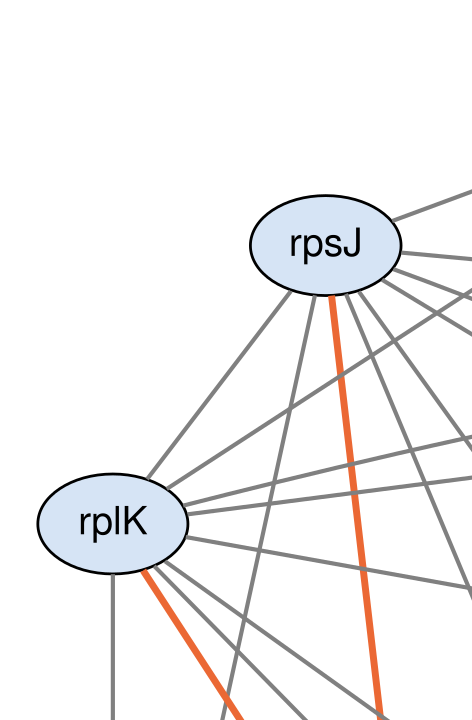

In [13]:
import graphviz as gv
from IPython.display import Image

NARANJA = "#eb6834"
AZUL = "#2a78d6"
VERDE = "#1baf7a"

def dibujar_vecindario(diana, k=12):
  nodos = [diana] + vecinos_mas_confiables(diana, k)
  graph = gv.Graph("Vecindario", engine="neato")
  graph.attr(overlap="false", sep="+20", splines="true", dpi="200")  # que no se encimen los nodos
  graph.attr("node", style="filled", fillcolor="#d6e4f5", fontname="Helvetica")
  graph.node(diana, fillcolor=NARANJA, fontcolor="white")
  for u in nodos:
    for v in grafo[u]:
      if v in nodos and u < v:  # u < v para no dibujar la misma arista 2 veces
        if diana in (u, v):
          graph.edge(u, v, color=NARANJA, penwidth="2.5")
        else:
          graph.edge(u, v, color="gray", penwidth="1.5")
  return graph

g = dibujar_vecindario("rpoB")
g.render("fig_vecindario_rpoB", format="png", cleanup=True)
g

## **12. Subgrafos de las dianas (BFS con profundidad limitada)**
Para cada diana guardamos las proteínas a distancia 2 o menos: `bfs(grafo, diana, max_nivel=2)`.

In [14]:
subgrafos = {}
print("Diana | Nivel 1 | Nivel 2 | Nodos | Aristas")
for diana in ["rpoB", "inhA", "embB"]:
  path, nivel = bfs(grafo, diana, max_nivel=2)

  n1 = 0
  n2 = 0
  for v in nivel:
    if nivel[v] == 1:
      n1 += 1
    elif nivel[v] == 2:
      n2 += 1

  # aristas que quedan dentro del subgrafo
  a = 0
  for u in nivel:
    for v in grafo[u]:
      if v in nivel and u < v:
        a += 1

  subgrafos[diana] = nivel
  print(diana, "|", n1, "|", n2, "|", len(nivel), "|", a)

Diana | Nivel 1 | Nivel 2 | Nodos | Aristas
rpoB | 160 | 869 | 1030 | 12822
inhA | 39 | 557 | 597 | 8586
embB | 36 | 548 | 585 | 9505


## **13. Dibujos de los subgrafos y del grafo completo (Graphviz)**
Para grafos grandes usamos el motor `sfdp` de Graphviz. Cada proteína es un punto.

In [15]:
def dibujar_grafo(nodos, colores, titulo, archivo):
  graph = gv.Graph("G", engine="sfdp")  # sfdp sirve para grafos grandes
  graph.attr(overlap="prism", outputorder="edgesfirst", label=titulo, fontsize="28",
             fontname="Helvetica", size="10,10", dpi="200")
  graph.attr("node", shape="point", width="0.06", color=AZUL)
  graph.attr("edge", color="#99999933")  # aristas grises casi transparentes

  for u in nodos:
    if u in colores and colores[u] == NARANJA:  # las dianas: círculo grande
      graph.node(u, shape="circle", label="", width="0.3", style="filled",
                 fillcolor=NARANJA, color="white")
    elif u in colores:                          # nivel 1 o 2: punto mediano
      graph.node(u, width="0.1", color=colores[u])
    else:                                       # el resto: punto pequeño
      graph.node(u)
  for u in nodos:
    for v in grafo[u]:
      if v in nodos and u < v:
        graph.edge(u, v)

  graph.render(archivo, format="png", cleanup=True)
  return Image(archivo + ".png", width=700)

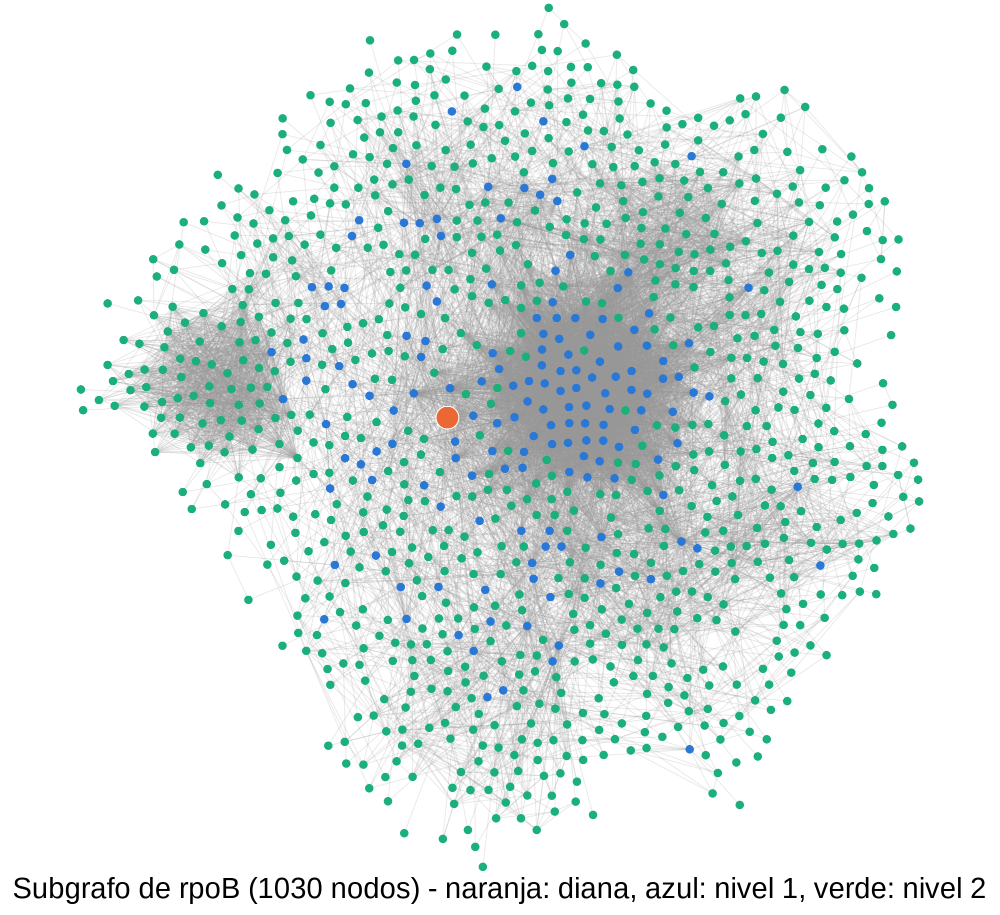

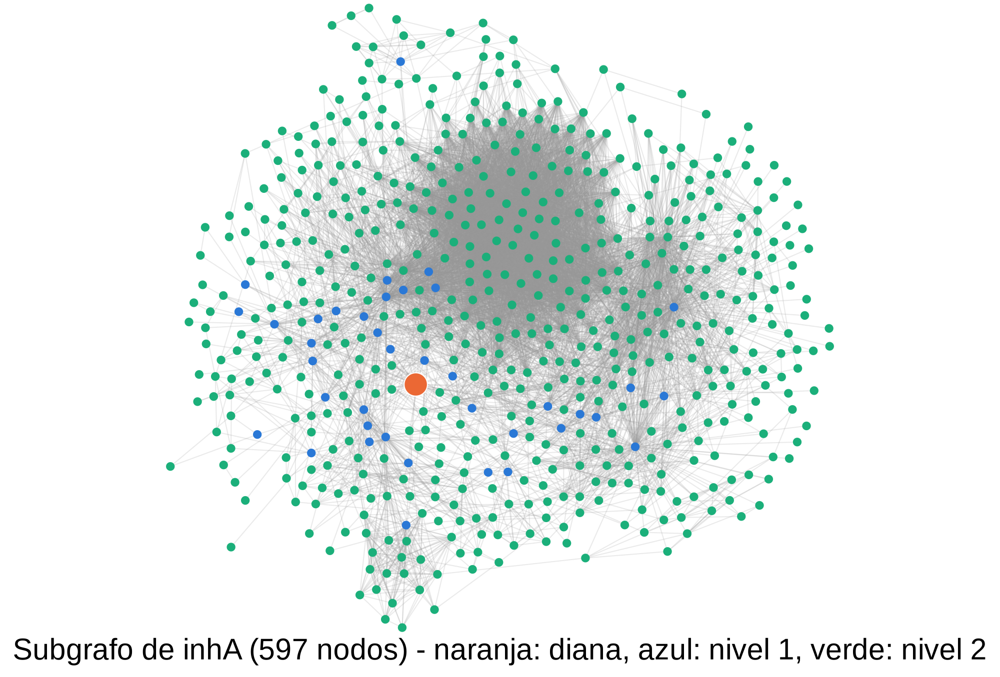

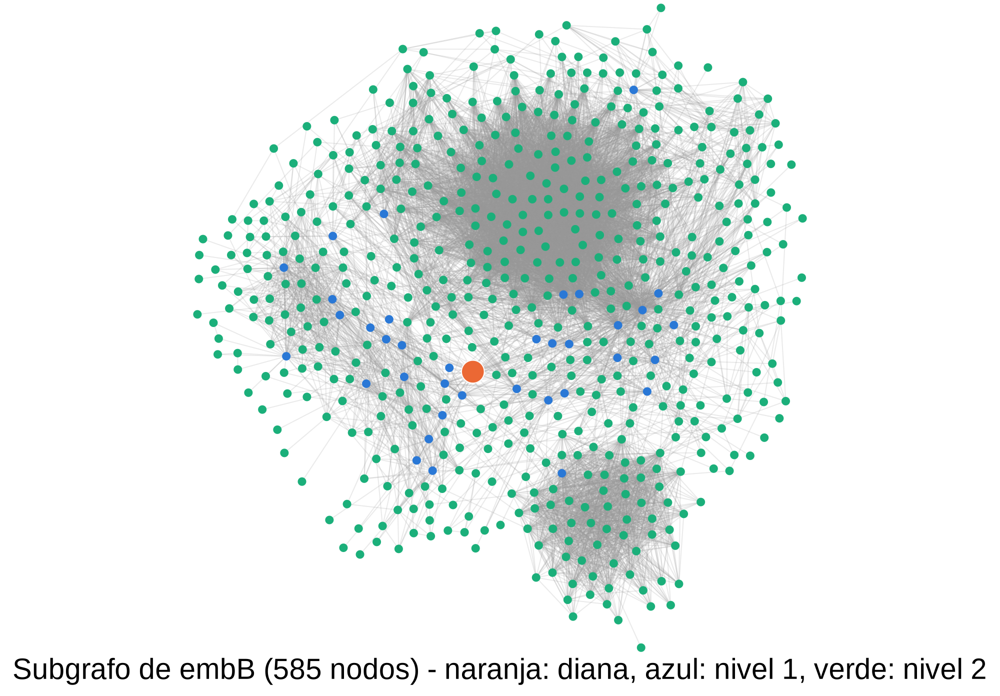

In [16]:
for diana in subgrafos:
  nivel = subgrafos[diana]
  colores = {}
  for v in nivel:
    if nivel[v] == 1:
      colores[v] = AZUL
    elif nivel[v] == 2:
      colores[v] = VERDE
  colores[diana] = NARANJA
  titulo = f"Subgrafo de {diana} ({len(nivel)} nodos) - naranja: diana, azul: nivel 1, verde: nivel 2"
  display(dibujar_grafo(set(nivel), colores, titulo, f"fig_subgrafo_{diana}"))

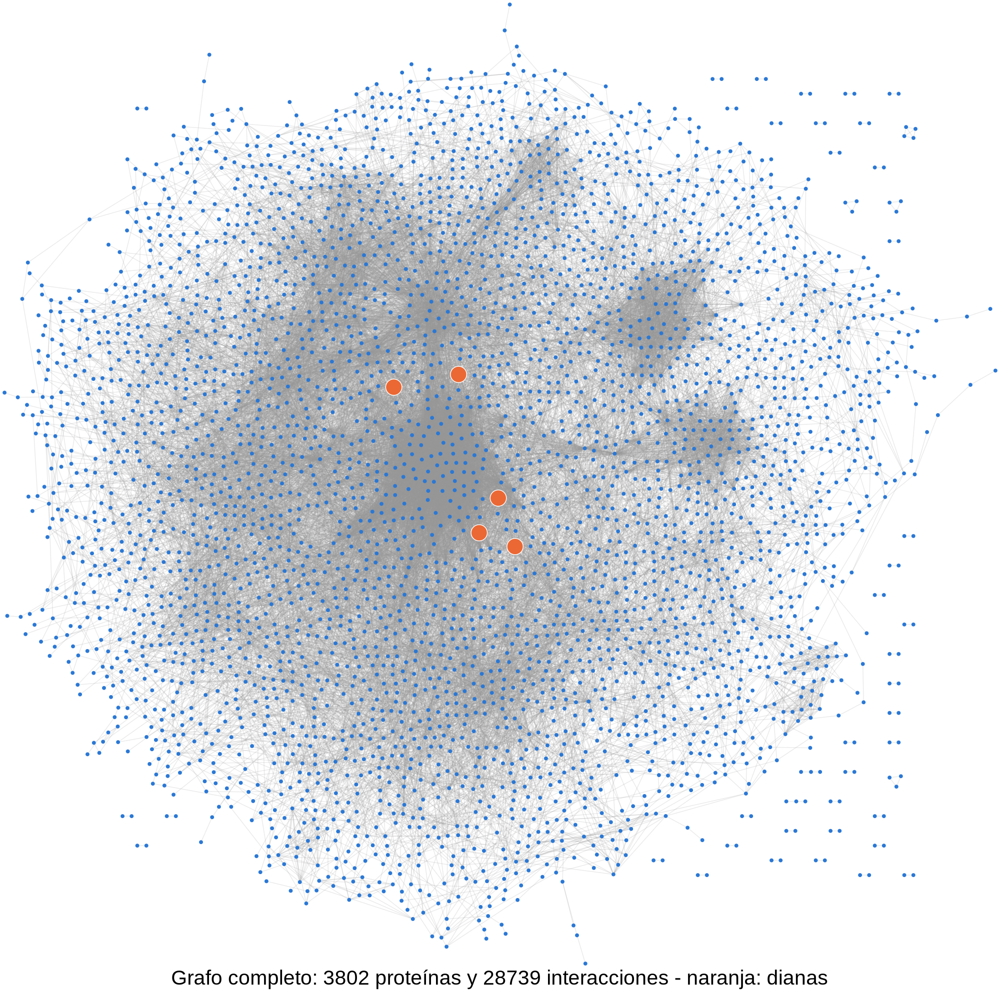

In [17]:
colores = {}
for d in DIANAS:
  colores[d] = NARANJA
titulo = f"Grafo completo: {N} proteínas y {aristas} interacciones - naranja: dianas"
dibujar_grafo(set(grafo), colores, titulo, "fig_grafo_completo")

## **14. Resumen y descarga de las figuras**

In [18]:
print("Proteínas en STRING:", len(nombre))
print("Nodos del grafo:", N)
print("Aristas:", aristas)
print("Componentes conexas:", len(comps_bfs), "- la mayor tiene", mayor, "nodos")
for diana in subgrafos:
  print("Subgrafo de", diana, ":", len(subgrafos[diana]), "nodos")

Proteínas en STRING: 4026
Nodos del grafo: 3802
Aristas: 28739
Componentes conexas: 46 - la mayor tiene 3705 nodos
Subgrafo de rpoB : 1030 nodos
Subgrafo de inhA : 597 nodos
Subgrafo de embB : 585 nodos


In [19]:
for archivo in ["fig_distribucion_grados.png", "fig_vecindario_rpoB.png", "fig_grafo_completo.png",
                "fig_subgrafo_rpoB.png", "fig_subgrafo_inhA.png", "fig_subgrafo_embB.png"]:
  files.download(archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **15. UFDS: componentes con conjuntos disjuntos**
Las mismas componentes de la sección 6, ahora con Quick-Find y Quick-Union (como en clase).

In [20]:
# UFDS trabaja con números: numeramos las proteínas (como w2i en clase)
labels = list(grafo.keys())   # labels[i] = nombre de la proteína i
w2i = {}                      # w2i["rpoB"] = número de rpoB
for i, u in enumerate(labels):
  w2i[u] = i

# Cada arista una sola vez (u < v)
lista_aristas = []
for u in grafo:
  for v in grafo[u]:
    if u < v:
      lista_aristas.append((w2i[u], w2i[v]))

print("Nodos:", len(labels), "- Aristas:", len(lista_aristas))

Nodos: 3802 - Aristas: 28739


In [21]:
# Quick-Find
def quickFind(s, a):
  return s[a]

def qf_Union(s, a, b):
  pa = quickFind(s, a)
  pb = quickFind(s, b)
  for i in range(len(s)):   # recorre todo el arreglo en cada unión
    if s[i] == pa:
      s[i] = pb


# Quick-Union
def find(s, a):
  i = a
  while s[i] != i:          # sube hasta la raíz
    i = s[i]
  return i

def union(s, a, b):
  pa = find(s, a)
  pb = find(s, b)
  s[pa] = pb                # solo cambia un padre

In [22]:
import time

ds = [i for i in range(len(labels))]
inicio = time.time()
for a, b in lista_aristas:
  qf_Union(ds, a, b)
t_quickfind = time.time() - inicio
print("Quick-Find : componentes =", len(set(ds)), "| tiempo =", round(t_quickfind, 3), "s")

s = [i for i in range(len(labels))]
inicio = time.time()
for a, b in lista_aristas:
  union(s, a, b)
raices = 0
for i in range(len(s)):
  if s[i] == i:             # una raíz = una componente
    raices += 1
t_quickunion = time.time() - inicio
print("Quick-Union: componentes =", raices, "| tiempo =", round(t_quickunion, 3), "s")

inicio = time.time()
comps = componentes_conexas(grafo, "bfs")
t_bfs_comp = time.time() - inicio
print("BFS        : componentes =", len(comps), "| tiempo =", round(t_bfs_comp, 3), "s")

Quick-Find : componentes = 46 | tiempo = 8.172 s
Quick-Union: componentes = 46 | tiempo = 2.662 s
BFS        : componentes = 46 | tiempo = 0.009 s


## **16. UCS: hallamos el camino más confiable**
Costo de cada arista: `−ln(puntaje / 1000)`. Así, el camino más barato es el más confiable.

In [23]:
import math
import heapq

def costo(u, v):
  return -math.log(peso[(u, v)] / 1000)

def reconstruir_ruta(path, t):
  ruta = []
  v = t
  while v != -1:
    ruta.append(v)
    v = path[v]
  ruta.reverse()
  return ruta

def ucs(G, s, t):
  dist = {s: 0}
  path = {s: -1}
  visited = {}
  cola = [(0, s)]                 # cola de prioridad: (costo, proteína)

  while cola:
    c, u = heapq.heappop(cola)    # sale la de menor costo
    if u in visited:
      continue
    visited[u] = True
    if u == t:
      break
    for v in G[u]:
      nuevo = c + costo(u, v)
      if v not in dist or nuevo < dist[v]:
        dist[v] = nuevo
        path[v] = u
        heapq.heappush(cola, (nuevo, v))

  ruta = reconstruir_ruta(path, t)
  confianza = math.exp(-dist[t])  # de costo a confianza
  return ruta, confianza

In [24]:
# Diana -> proteína de resistencia (Comas et al., 2012; Billows et al., 2024)
PARES = [("rpoB", "rpoA"), ("rpoB", "rpoC"),
         ("katG", "ahpC"), ("inhA", "ahpC"),
         ("rpoB", "katG"), ("rpoB", "inhA")]

for s, t in PARES:
  ruta, conf = ucs(grafo, s, t)
  print(s, "->", t, "|", " - ".join(ruta), "|", round(conf, 3))

rpoB -> rpoA | rpoB - rpoA | 0.999
rpoB -> rpoC | rpoB - rpoC | 0.999
katG -> ahpC | katG - ahpC | 0.964
inhA -> ahpC | inhA - ahpC | 0.961
rpoB -> katG | rpoB - katG | 0.952
rpoB -> inhA | rpoB - inhA | 0.961


Si se bloquea la interacción directa:

In [25]:
def sin_arista(G, s, t):
  G2 = {}
  for u in G:
    G2[u] = []
    for v in G[u]:
      if not ((u == s and v == t) or (u == t and v == s)):
        G2[u].append(v)
  return G2

for s, t in PARES:
  ruta, conf = ucs(sin_arista(grafo, s, t), s, t)
  print(s, "->", t, "|", " - ".join(ruta), "|", round(conf, 3))

rpoB -> rpoA | rpoB - rpoC - rpoA | 0.998
rpoB -> rpoC | rpoB - rpoA - rpoC | 0.998
katG -> ahpC | katG - rpoB - ahpC | 0.918
inhA -> ahpC | inhA - rpoB - ahpC | 0.926
rpoB -> katG | rpoB - ahpC - katG | 0.929
rpoB -> inhA | rpoB - fabG1 - inhA | 0.959


## **17. Backtracking: buscamos las otras rutas**
Todas las rutas de hasta L pasos. No guardamos las rutas: contamos al vuelo qué proteínas intermedias se repiten (candidatas a co-dianas).

In [26]:
def rutas_backtracking(G, s, t, L, conf_min):
  cuenta = {}                 # cuántas rutas pasan por cada proteína intermedia
  ruta = [s]
  en_ruta = {s: True}         # control de ciclos: una proteína no se repite en la ruta
  total = {"rutas": 0, "llamadas": 0}

  def bt(u, conf):
    total["llamadas"] += 1
    if u == t:
      total["rutas"] += 1
      for x in ruta[1:-1]:    # contamos al vuelo, sin guardar la ruta
        if x not in cuenta:
          cuenta[x] = 0
        cuenta[x] += 1
      return
    if len(ruta) - 1 == L:    # poda: máximo L pasos (la recursión nunca pasa de L)
      return
    for v in G[u]:
      if v in en_ruta:
        continue
      nueva = conf * peso[(u, v)] / 1000
      if nueva < conf_min:    # poda: confianza mínima
        continue
      ruta.append(v)
      en_ruta[v] = True
      bt(v, nueva)
      ruta.pop()              # retroceder
      del en_ruta[v]

  bt(s, 1.0)
  return total["rutas"], cuenta, total["llamadas"]


def intermedias_frecuentes(cuenta, k):
  orden = []
  for n in range(max(cuenta.values(), default=0), 0, -1):
    for x in cuenta:
      if cuenta[x] == n:
        orden.append((x, n))
  return orden[:k]

In [27]:
for s, t in [("inhA", "ahpC"), ("rpoB", "katG"), ("rpoB", "inhA")]:
  rutas, cuenta, llamadas = rutas_backtracking(grafo, s, t, 3, 0.9)
  print(s, "->", t, ":", rutas, "rutas (L <= 3, confianza >= 0.9)")
  print("   Intermedias:", intermedias_frecuentes(cuenta, 6))

inhA -> ahpC : 14 rutas (L <= 3, confianza >= 0.9)
   Intermedias: [('fabG1', 6), ('rpoB', 5), ('kasA', 4), ('katG', 2), ('kasB', 2), ('gyrB', 1)]
rpoB -> katG : 45 rutas (L <= 3, confianza >= 0.9)
   Intermedias: [('rpsL', 34), ('gyrA', 4), ('gyrB', 3), ('pncA', 3), ('fabG1', 2), ('rpsA', 2)]
rpoB -> inhA : 59 rutas (L <= 3, confianza >= 0.9)
   Intermedias: [('rpsL', 41), ('gyrA', 8), ('fabG1', 6), ('pncA', 4), ('gyrB', 3), ('embB', 3)]


Costo teórico vs. medido (katG -> ahpC). Peor caso: grado_max^L llamadas.

In [28]:
print("L | peor caso | llamadas sin poda | llamadas con poda 0.9 | rutas | tiempo (s)")
for L in [1, 2, 3, 4]:
  inicio = time.time()
  rutas, cuenta, llamadas = rutas_backtracking(grafo, "katG", "ahpC", L, 0.0)
  t_bt = round(time.time() - inicio, 2)
  rutas09, cuenta09, llamadas09 = rutas_backtracking(grafo, "katG", "ahpC", L, 0.9)
  print(L, "|", grado_max ** L, "|", llamadas, "|", llamadas09, "|", rutas, "|", t_bt)

L | peor caso | llamadas sin poda | llamadas con poda 0.9 | rutas | tiempo (s)
1 | 164 | 34 | 22 | 1 | 0.0
2 | 26896 | 1353 | 203 | 21 | 0.0
3 | 4410944 | 84076 | 6322 | 244 | 0.07
4 | 723394816 | 6630313 | 293041 | 4850 | 6.73


Memoria: guardar todas las rutas vs. contarlas al vuelo (L = 4).

In [29]:
import tracemalloc

def rutas_guardando(G, s, t, L):
  rutas = []
  ruta = [s]
  def bt(u):
    if u == t:
      rutas.append(list(ruta))   # guarda cada ruta completa
      return
    if len(ruta) - 1 == L:
      return
    for v in G[u]:
      if v not in ruta:
        ruta.append(v)
        bt(v)
        ruta.pop()
  bt(s)
  return rutas

tracemalloc.start()
guardadas = rutas_guardando(grafo, "katG", "ahpC", 4)
pico_guardando = tracemalloc.get_traced_memory()[1]
tracemalloc.stop()

tracemalloc.start()
rutas_backtracking(grafo, "katG", "ahpC", 4, 0.0)
pico_contando = tracemalloc.get_traced_memory()[1]
tracemalloc.stop()

print(len(guardadas), "rutas | guardando:", round(pico_guardando / 1024), "KB | contando:", round(pico_contando / 1024), "KB")

4850 rutas | guardando: 551 KB | contando: 29 KB


## **18. Ford-Fulkerson: ¿cuántos caminos independientes hay?**
Capacidad 1 por interacción: el flujo máximo es el número de caminos que no comparten interacciones.
Es el algoritmo de clase, pero sobre la lista de adyacencia (la matriz sería de 3802 x 3802).

In [30]:
def BFS(cap, G, s, t, parent):
  visited = {s: True}
  queue = [s]
  while queue:
    u = queue.pop(0)
    for v in G[u]:
      if v not in visited and cap[(u, v)] > 0:
        visited[v] = True
        parent[v] = u
        queue.append(v)
  return t in visited


def FordFulkerson(G, source, sink):
  cap = {}
  for u in G:
    for v in G[u]:
      cap[(u, v)] = 1
  parent = {}
  max_flow = 0

  while BFS(cap, G, source, sink, parent):
    path_flow = float("Inf")
    s = sink
    while s != source:
      path_flow = min(path_flow, cap[(parent[s], s)])
      s = parent[s]
    max_flow += path_flow

    v = sink
    while v != source:
      u = parent[v]
      cap[(u, v)] -= path_flow
      cap[(v, u)] += path_flow
      v = parent[v]
    parent = {}
  return max_flow

In [31]:
for s, t in PARES:
  flujo = FordFulkerson(grafo, s, t)
  print(s, "->", t, "| flujo máximo:", flujo, "| grados:", len(grafo[s]), len(grafo[t]))

rpoB -> rpoA | flujo máximo: 144 | grados: 160 144
rpoB -> rpoC | flujo máximo: 112 | grados: 160 112
katG -> ahpC | flujo máximo: 33 | grados: 33 33
inhA -> ahpC | flujo máximo: 33 | grados: 39 33
rpoB -> katG | flujo máximo: 33 | grados: 160 33
rpoB -> inhA | flujo máximo: 39 | grados: 160 39


## **19. Kruskal: el esqueleto de la red (MST)**

De las 28 739 interacciones nos quedamos con las mínimas para que todo siga conectado, eligiendo siempre las más confiables.
Usa el mismo costo que UCS y el `find` de la sección 15.

In [32]:
# Unión por rango (como applyUnion en clase): el árbol más bajo se cuelga del más alto
def union_rango(parent, rank, x, y):
  if rank[x] < rank[y]:
    parent[x] = y
  elif rank[x] > rank[y]:
    parent[y] = x
  else:
    parent[y] = x
    rank[x] += 1


def kruskal(G, rango=True):
  # 1. Cada arista una sola vez, con su costo
  aristas_costo = []
  for u in G:
    for v in G[u]:
      if u < v:
        aristas_costo.append((costo(u, v), u, v))
  aristas_costo.sort()            # de menor a mayor costo = de la más confiable a la menos

  # 2. Cada proteína empieza sola en su conjunto
  parent = [i for i in range(len(labels))]
  rank = [0 for i in range(len(labels))]

  # 3. Tomamos la arista solo si une dos conjuntos distintos (si no, formaría un ciclo)
  arbol = []
  for c, u, v in aristas_costo:
    x = find(parent, w2i[u])
    y = find(parent, w2i[v])
    if x != y:
      arbol.append((u, v))
      if rango:
        union_rango(parent, rank, x, y)
      else:
        parent[x] = y             # Quick-Union simple de la sección 15
  return arbol

In [33]:
inicio = time.time()
arbol = kruskal(grafo)
t_kruskal = time.time() - inicio

inicio = time.time()
kruskal(grafo, rango=False)
t_kruskal_simple = time.time() - inicio

suma_grafo = 0
for u in grafo:
  for v in grafo[u]:
    if u < v:
      suma_grafo += peso[(u, v)]
suma_mst = 0
for u, v in arbol:
  suma_mst += peso[(u, v)]

print("Aristas del grafo:", aristas)
print("Aristas del MST  :", len(arbol), "-", round(100 * len(arbol) / aristas, 1), "% del grafo")
print("Nodos - componentes:", N, "-", len(comps_bfs), "=", N - len(comps_bfs))
print("Puntaje promedio : grafo", round(suma_grafo / aristas), "| MST", round(suma_mst / len(arbol)))
print("Tiempo con unión por rango:", round(t_kruskal, 3), "s | con Quick-Union simple:", round(t_kruskal_simple, 3), "s")

Aristas del grafo: 28739
Aristas del MST  : 3756 - 13.1 % del grafo
Nodos - componentes: 3802 - 46 = 3756
Puntaje promedio : grafo 847 | MST 918
Tiempo con unión por rango: 0.081 s | con Quick-Union simple: 0.701 s


El MST como lista de adyacencia, para recorrerlo con lo que ya tenemos:

In [34]:
mst = {}
for u in grafo:
  mst[u] = []
for u, v in arbol:
  mst[u].append(v)
  mst[v].append(u)

print("Componentes del MST:", len(componentes_conexas(mst, "bfs")))
for d in DIANAS:
  print(d, "| vecinas en el grafo:", len(grafo[d]), "| en el MST:", len(mst[d]))

Componentes del MST: 46
rpoB | vecinas en el grafo: 160 | en el MST: 10
inhA | vecinas en el grafo: 39 | en el MST: 5
katG | vecinas en el grafo: 33 | en el MST: 5
embB | vecinas en el grafo: 36 | en el MST: 3
gyrA | vecinas en el grafo: 39 | en el MST: 3


En un árbol hay un solo camino entre dos proteínas: el MST sirve para **ver** la red, no para buscar rutas.

In [35]:
for s, t in [("rpoB", "katG"), ("rpoB", "inhA")]:
  path, nivel = bfs(mst, s)
  ruta_mst = reconstruir_ruta(path, t)
  ruta_ucs, conf = ucs(grafo, s, t)
  print(s, "->", t, "| en el MST:", len(ruta_mst) - 1, "pasos | con UCS en el grafo:", len(ruta_ucs) - 1, "paso(s)")

rpoB -> katG | en el MST: 2 pasos | con UCS en el grafo: 1 paso(s)
rpoB -> inhA | en el MST: 28 pasos | con UCS en el grafo: 1 paso(s)


In [36]:
def dibujar_arbol(arbol, titulo, archivo):
  graph = gv.Graph("MST", engine="sfdp")
  graph.attr(overlap="prism", outputorder="edgesfirst", label=titulo, fontsize="28",
             fontname="Helvetica", size="10,10", dpi="200")
  graph.attr("node", shape="point", width="0.06", color=AZUL)
  graph.attr("edge", color="#88888899")
  for d in DIANAS:                # las dianas: círculo grande naranja
    graph.node(d, shape="circle", label="", width="0.3", style="filled",
               fillcolor=NARANJA, color="white")
  for u, v in arbol:
    graph.edge(u, v)
  graph.render(archivo, format="png", cleanup=True)
  return Image(archivo + ".png", width=700)

titulo = f"Esqueleto de la red (MST): {N} proteínas y {len(arbol)} interacciones - naranja: dianas"
dibujar_arbol(arbol, titulo, "fig_mst")
files.download("fig_mst.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **20. Tiempo de cada algoritmo**

In [37]:
def medir(funcion):
  inicio = time.time()
  funcion()
  return round(time.time() - inicio, 4)

print("BFS desde rpoB              | O(V + E)         |", medir(lambda: bfs(grafo, "rpoB")))
print("Componentes con BFS         | O(V + E)         |", round(t_bfs_comp, 4))
print("Componentes con Quick-Union | O(E * altura)    |", round(t_quickunion, 4))
print("Componentes con Quick-Find  | O(V * E)         |", round(t_quickfind, 4))
print("UCS rpoB -> rpoA            | O((V + E) log V) |", medir(lambda: ucs(grafo, "rpoB", "rpoA")))
print("Backtracking rpoB -> katG   | O(Δ^L)           |", medir(lambda: rutas_backtracking(grafo, "rpoB", "katG", 3, 0.0)))
print("Ford-Fulkerson rpoB -> rpoA | O(f * (V + E))   |", medir(lambda: FordFulkerson(grafo, "rpoB", "rpoA")))
print("Kruskal (MST)               | O(E log E)       |", round(t_kruskal, 4))

BFS desde rpoB              | O(V + E)         | 0.0069
Componentes con BFS         | O(V + E)         | 0.0094
Componentes con Quick-Union | O(E * altura)    | 2.6623
Componentes con Quick-Find  | O(V * E)         | 8.1722
UCS rpoB -> rpoA            | O((V + E) log V) | 0.0002
Backtracking rpoB -> katG   | O(Δ^L)           | 0.7617
Ford-Fulkerson rpoB -> rpoA | O(f * (V + E))   | 1.0615
Kruskal (MST)               | O(E log E)       | 0.0807
